<a href="https://colab.research.google.com/github/PBBzone/Deep-Learning/blob/DAY-5/DL_training_day_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
https://www.tensorflow.org/tutorials/generative/dcgan

- what is GAN
  GAN stands for generative adversarial network.
  it is a deep learning architechture used to generate new data that looks similar to the training data.
for example -
  - generate human faces
  - generate handwritten digits
  - generate cartoon images
  - generate artificial product images
  - generate realistic images

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers
# Explanation:
# - tensorflow: deep learning framework
# - numpy: handles numerical operations
# - matplotlib: dispaly images
# - layers: provides dense, conv2d, flatten, etc

# step 3: load the MNIST dataset
# MNIST contains 70,000 handwritten digit images
# - 60,000 training images
# - 10,000 testing images
# - each images has dimensions 28 x 28
# - each image contains a digit between 0 ad 9



In [ ]:
# load MNIST dataset

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# check dataset shape
print("training data:", x_train.shape)
print("testing data:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
training data: (60000, 28, 28)
testing data: (10000, 28, 28)


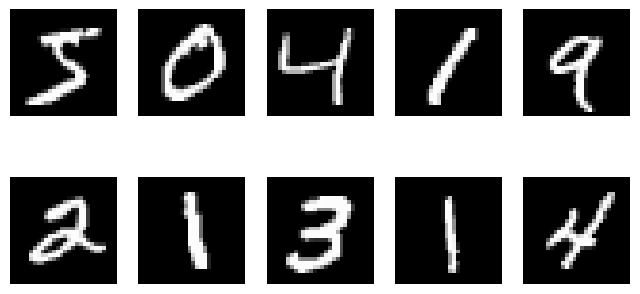

In [ ]:
#display some original images
plt.figure(figsize=(8,4))
for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(x_train[i], cmap='gray')
  plt.axis('off')

plt.show()

In [ ]:
# step 4: preprocess the images
# our original pixel values range from 0 to 255
# we ned to normalize these values between -1 and +1
# why?
# because our generator will use the tanh activation function
# which produces values between -1 and +1
# convert images to float32


x_train = x_train.astype("float32")
# Normalize pixel values from 0-255 to -1 to +1
x_train = (x_train - 127.5) / 127.5
# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
print(x_train.shape)

# Why do we add the channel dimension? I
# Because CNN models expect image data in this format:
# (Height, Width)

(60000, 28, 28, 1)


In [ ]:
#Step 5: Prepare the training dataset
BUFFER_SIZE = 60000
BATCH_SIZE = 256
train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE)
train_dataset = train_dataset.batch(BATCH_SIZE)

# Explanation:
# - shuffle(): Randomly changes image order.
# - batch(): divides images into groups of 256

In [ ]:
# Step 6: Create the Generator
# Now we will build our first neural network.
# The Generator takes 100 random numbers and generates a 28 × 28 image.
def build_generator():
    model = tf.keras.Sequential()
    # Input: 100 random numbers
    model.add(layers.Input(shape=(100,)))
    # Convert noise into 7*7*128 values
    model.add(layers.Dense(7 * 7 * 128))

    # Normalize values
    model.add(layers.BatchNormalization())

    # Apply activation
    model.add(layers.LeakyReLU())

    # Reshape into feature maps
    model.add(layers.Reshape((7, 7, 128)))

    # Increase image size from 7x7 to 14x14
    model.add(
        layers.Conv2DTranspose(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.BatchNormalization())

    model.add(layers.LeakyReLU())

    # Increase image size from 14x14 to 28x28
    model.add(
        layers.Conv2DTranspose(
            1,
            kernel_size=5,
            strides=2,
            padding="same",
            activation="tanh"
        )
    )

    return model

In [ ]:
# Let's understand the important layers.
# Layer	                          Purpose
# Dense	                          Converts random noise into feature values
# Batch                           Normalization	Stabilizes training
# Leaky                           ReLU	Adds non-linearity
# Reshape                       	Converts features into 7 × 7 feature maps
# Conv2D                          Transpose	Upsamples feature maps
# Tanh	                          Generates pixel values between -1 and +1

In [ ]:
#create the Generator:
generator = build_generator()
generator.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,864 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865,281 (3.30 MB)

 Trainable params: 852,609 (3.25 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [ ]:
# generate 1 random noise vector

noise = tf.random.normal([1, 100])
#generate an image
generated_image = generator(noise, training=False)
print(generated_image.shape)

(1, 28, 28, 1)


In [ ]:
# Step 7: Create the Discriminator
# Now let's create the second neural network.
# The Discriminator receives an image and predicts whether it is real or fake.
def build_discriminator():

    model = tf.keras.Sequential()

    # Input image: 28x28 grayscale
    model.add(layers.Input(shape=(28, 28, 1)))

    # First convolution layer
    model.add(
        layers.Conv2D(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Second convolution layer
    model.add(
        layers.Conv2D(
            128,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Convert feature maps into a vector
    model.add(layers.Flatten())

    # Final output
    model.add(layers.Dense(1))

    return model

In [ ]:
discriminator = build_discriminator()
discriminator.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Important: The final Dense layer has one output and no sigmoid activation. It produces a raw score called a logit.
# - Higher score: More likely to be real.
# - Lower score: More likely to be fake.
# We will use BinaryCrossentropy(from_logits=True) to calculate the loss.
# Step 8: Define loss functions
# Now comes the most important part of GAN training.
# We need two loss functions.
# 1. Generator Loss
# 2. Discriminator Loss


In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

In [ ]:
# Discriminator Loss:
# The Discriminator should identify real images as 1 and fake images as 0.
def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss

In [ ]:
def generator_loss(fake_output):

    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

In [ ]:
# Step 9: Define optimizers
# We use Adam optimizers to update the weights of both networks.
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

# Why two optimizers?
# Because the Generator and Discriminator have different trainable weights
# and are trained separately.

In [ ]:
# Define noise dimension

noise_dim = 100


@tf.function
def train_step(real_images):

    # Number of images in current batch
    batch_size = tf.shape(real_images)[0]

    # Generate random noise
    noise = tf.random.normal([batch_size, noise_dim])

    # --------------------------------
    # Train Discriminator
    # --------------------------------

    with tf.GradientTape() as disc_tape:

        # Generate fake images
        generated_images = generator(noise, training=True)

        # Discriminator predictions on real images
        real_output = discriminator(
            real_images,
            training=True
        )

        # Discriminator predictions on fake images
        fake_output = discriminator(
            tf.stop_gradient(generated_images),
            training=True
        )

        # Calculate discriminator loss
        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    # Calculate gradients
    disc_gradients = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    # Update discriminator weights
    discriminator_optimizer.apply_gradients(
        zip(
            disc_gradients,
            discriminator.trainable_variables
        )
    )

    # --------------------------------
    # Train Generator
    # --------------------------------

    noise = tf.random.normal([batch_size, noise_dim])

    with tf.GradientTape() as gen_tape:

        # Generate new fake images
        generated_images = generator(
            noise,
            training=True
        )

        # Ask discriminator to classify fake images
        fake_output = discriminator(
            generated_images,
            training=True
        )

        # Generator wants fake images to be classified as real
        gen_loss = generator_loss(fake_output)

    # Calculate generator gradients
    gen_gradients = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    # Update generator weights
    generator_optimizer.apply_gradients(
        zip(
            gen_gradients,
            generator.trainable_variables
        )
    )

    return gen_loss, disc_loss

In [ ]:
# Step 11: Train the GAN model
# Now we will train both networks.
EPOCHS = 3

# Fallback to recreate train_dataset if it is missing in the current runtime state
try:
    train_dataset
except NameError:
    print("train_dataset was not found. Re-creating train_dataset from x_train...")
    BUFFER_SIZE = 60000
    BATCH_SIZE = 256
    train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
    train_dataset = train_dataset.shuffle(BUFFER_SIZE)
    train_dataset = train_dataset.batch(BATCH_SIZE)

for epoch in range(EPOCHS):

    gen_loss_total = 0
    disc_loss_total = 0
    batches = 0

    for image_batch in train_dataset:

        gen_loss, disc_loss = train_step(image_batch)

        gen_loss_total += gen_loss
        disc_loss_total += disc_loss

        batches += 1

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {gen_loss_total / batches:.4f} | "
        f"Discriminator Loss: {disc_loss_total / batches:.4f}"
    )

Epoch 1/3 | Generator Loss: 0.8431 | Discriminator Loss: 1.2648
Epoch 2/3 | Generator Loss: 0.8967 | Discriminator Loss: 1.2235
Epoch 3/3 | Generator Loss: 0.9340 | Discriminator Loss: 1.2165


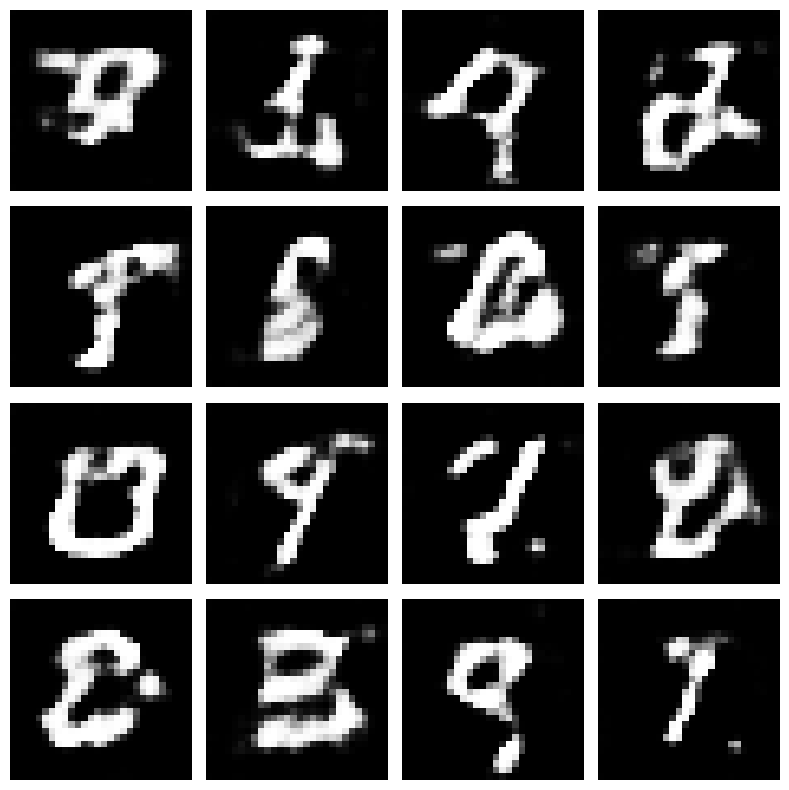

In [19]:
# Step 12: Generate new images
# Final output
# Now our Generator has learned from the MNIST dataset.
# Let's generate 16 new images.
# Generate 16 random noise vectors

noise = tf.random.normal([16, noise_dim])

# Generate images

predictions = generator(noise, training=False)

# Display generated images

plt.figure(figsize=(8, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    # Convert pixel values from -1 to +1 into 0 to 1
    image = (predictions[i, :, :, 0] + 1) / 2

    plt.imshow(image, cmap="gray")

    plt.axis("off")

plt.tight_layout()

plt.show()